In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

data_path = Path("perceptron_data.csv")
if not data_path.exists():
    data_path = Path("Lab Works/Lab-3/perceptron_data.csv")

data = pd.read_csv(data_path)
X = data[["x1", "x2"]].to_numpy()
y = data["y"].to_numpy()

print("Number of examples:", len(data))
display(data.head())

Number of examples: 100


,x1,x2,y
0,6.822060,7.896793,1
1,7.886186,6.174578,1
2,6.227460,7.307143,1
3,2.097078,2.968645,-1
4,1.470240,2.513267,-1


## 1. Decision Boundary Investigation

In [15]:
def initialize_parameters():
    return np.random.uniform(-1, 1, 3)


def plot_decision_boundary(X, y, weights, title):
    plt.scatter(X[y == -1, 0], X[y == -1, 1], color="blue", label="Class -1")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color="orange", label="Class +1")

    w0, w1, w2 = weights
    x_values = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)

    if w2 != 0:
        y_values = -(w0 + w1 * x_values) / w2
        plt.plot(x_values, y_values, color="black", label="Decision boundary")
    elif w1 != 0:
        plt.axvline(-w0 / w1, color="black", label="Decision boundary")

    plt.xlim(X[:, 0].min() - 1, X[:, 0].max() + 1)
    plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)

Random weights [w0, w1, w2]: [-0.84738342  0.55983758 -0.12318154]


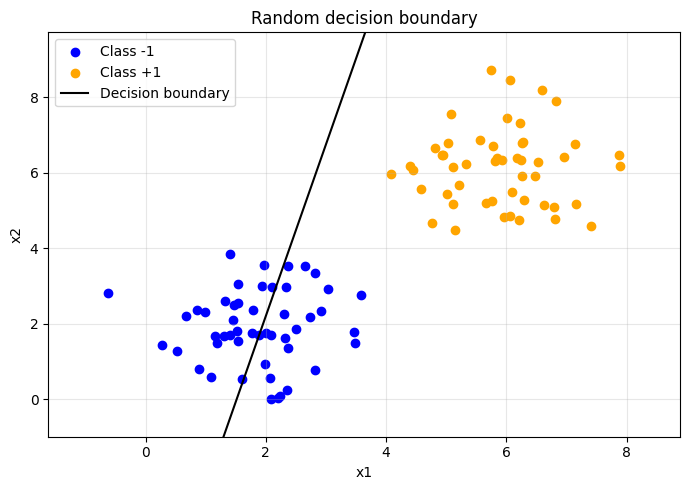

In [16]:
np.random.seed(7)
initial_weights = initialize_parameters()
print("Random weights [w0, w1, w2]:", initial_weights)

plt.figure(figsize=(7, 5))
plot_decision_boundary(X, y, initial_weights, "Random decision boundary")
plt.tight_layout()
plt.show()

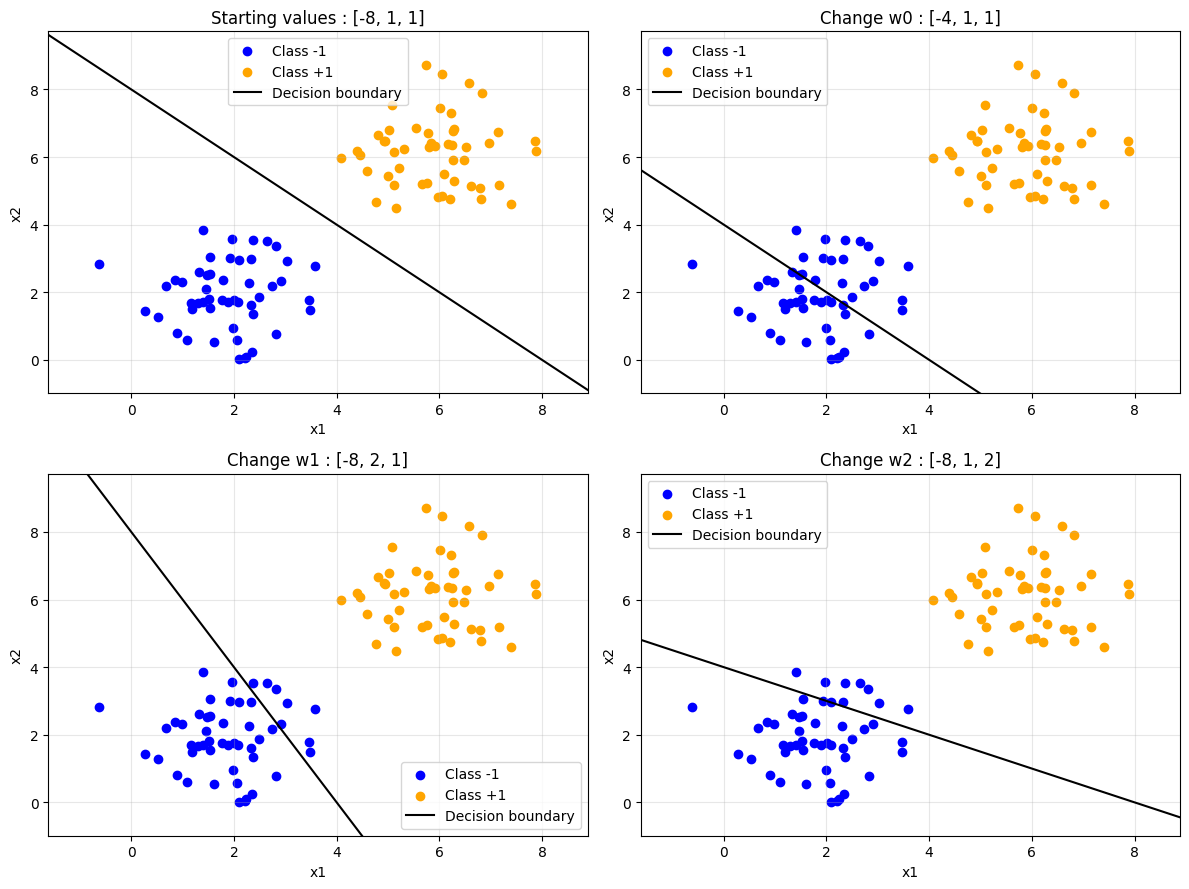

Changing w0 shifts the line without changing its slope.
Changing w1 or w2 changes the slope of the line.


In [17]:
manual_weights = [
    [-8, 1, 1],
    [-4, 1, 1],
    [-8, 2, 1],
    [-8, 1, 2]
]

titles = ["Starting values", "Change w0", "Change w1", "Change w2"]

plt.figure(figsize=(12, 9))
for i in range(len(manual_weights)):
    plt.subplot(2, 2, i + 1)
    weights = manual_weights[i]
    title = titles[i] + " : " + str(weights)
    plot_decision_boundary(X, y, weights, title)

plt.tight_layout()
plt.show()

print("Changing w0 shifts the line without changing its slope.")
print("Changing w1 or w2 changes the slope of the line.")

## 2. Perceptron from Scratch

In [18]:
def predict(x, weights):
    score = weights[0] + weights[1] * x[0] + weights[2] * x[1]
    if score >= 0:
        return 1
    return -1


def compute_loss(X, y, weights):
    errors = 0
    for i in range(len(X)):
        prediction = predict(X[i], weights)
        if prediction != y[i]:
            errors += 1
    return errors


def update_weights(weights, x, y, learning_rate):
    weights[0] = weights[0] + learning_rate * y
    weights[1] = weights[1] + learning_rate * y * x[0]
    weights[2] = weights[2] + learning_rate * y * x[1]
    return weights


def train_perceptron(X, y, weights, learning_rate, epochs, weight_history=None):
    weights = weights.copy()
    error_history = []

    if weight_history is not None:
        weight_history.clear()
        weight_history.append(weights.copy())

    errors = compute_loss(X, y, weights)
    if errors == 0:
        return weights, error_history

    for epoch in range(epochs):
        for i in range(len(X)):
            prediction = predict(X[i], weights)
            score = weights[0] + weights[1] * X[i, 0] + weights[2] * X[i, 1]

            if prediction != y[i] or score == 0:
                weights = update_weights(weights, X[i], y[i], learning_rate)

            if weight_history is not None:
                weight_history.append(weights.copy())

            errors = compute_loss(X, y, weights)
            if errors == 0:
                error_history.append(errors)
                return weights, error_history

        error_history.append(errors)

    return weights, error_history

## 3. Visualize Perceptron Learning

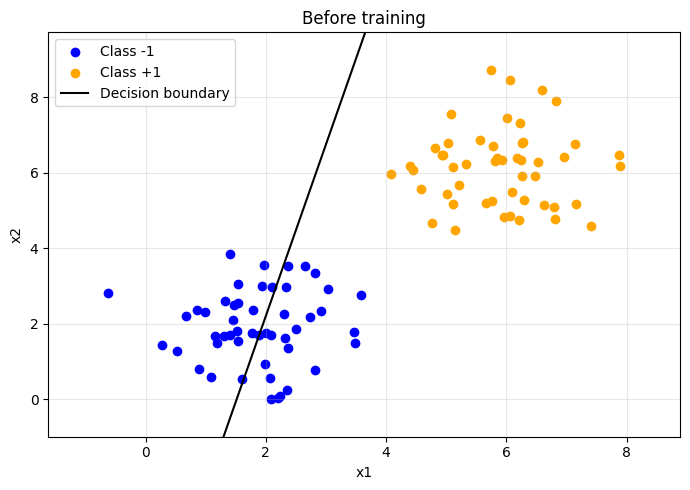

Initial weights: [-0.84738342  0.55983758 -0.12318154]
Final weights: [-0.98738342  0.25589072  0.01171913]
Initial classification errors: 23
Final classification errors: 0
Training iterations: 372


,Epoch,Classification errors
0,1,5
1,2,7
2,3,3
3,4,0


In [19]:
learning_rate = 0.01
epochs = 50
initial_errors = compute_loss(X, y, initial_weights)

plt.figure(figsize=(7, 5))
plot_decision_boundary(X, y, initial_weights, "Before training")
plt.tight_layout()
plt.show()

weight_history = []
final_weights, error_history = train_perceptron(
    X, y, initial_weights, learning_rate, epochs, weight_history
)

print("Initial weights:", initial_weights)
print("Final weights:", final_weights)
print("Initial classification errors:", initial_errors)
print("Final classification errors:", compute_loss(X, y, final_weights))

print("Training iterations:", len(weight_history) - 1)

display(pd.DataFrame({
    "Epoch": range(1, len(error_history) + 1),
    "Classification errors": error_history
}))

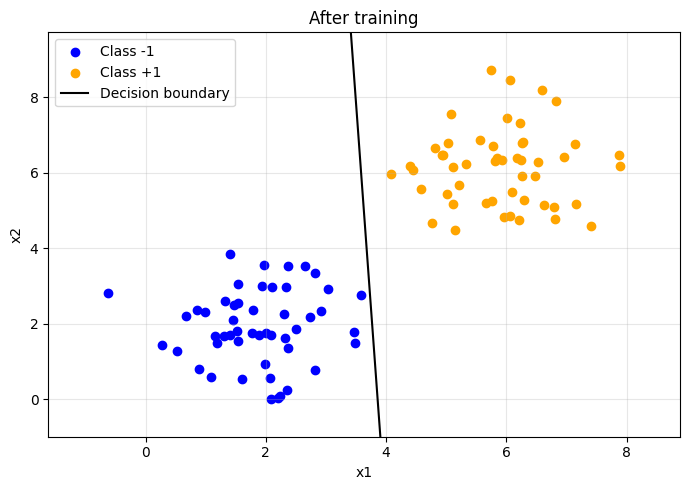

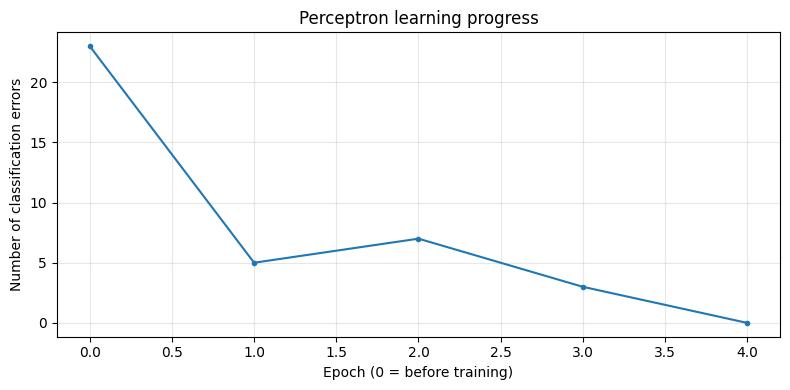

In [20]:
plt.figure(figsize=(7, 5))
plot_decision_boundary(X, y, final_weights, "After training")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(len(error_history) + 1), [initial_errors] + error_history, marker="o", markersize=3)
plt.xlabel("Epoch (0 = before training)")
plt.ylabel("Number of classification errors")
plt.title("Perceptron learning progress")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
predictions = []
for x in X:
    predictions.append(predict(x, final_weights))

results = data.copy()
results["Prediction"] = predictions
display(results.head(10))

final_errors = compute_loss(X, y, final_weights)
accuracy = (len(y) - final_errors) / len(y) * 100
print("Training accuracy:", accuracy, "%")

,x1,x2,y,Prediction
0,6.822060,7.896793,1,1
1,7.886186,6.174578,1,1
2,6.227460,7.307143,1,1
3,2.097078,2.968645,-1,-1
4,1.470240,2.513267,-1,-1
5,2.091761,0.012431,-1,-1
6,0.521478,1.280156,-1,-1
7,5.025318,6.787085,1,1
8,3.465649,1.774224,-1,-1
9,2.496714,1.861736,-1,-1


Training accuracy: 100.0 %


In [22]:
first_zero_epoch = 0 if initial_errors == 0 else None
for i in range(len(error_history)):
    if error_history[i] == 0:
        first_zero_epoch = i + 1
        break

print("1. The decision boundary shifted and rotated during training.")
print("   The final line separates the two classes in the training data.")

if first_zero_epoch == 0:
    print("2. The initial weights already classified every example correctly.")
elif first_zero_epoch is not None:
    print("2. Training stopped with zero errors during epoch", first_zero_epoch)
else:
    print("2. The model still had training errors after", epochs, "epochs.")

if final_errors == 0:
    print("3. Yes, the final model correctly classified all", len(y), "training examples.")
else:
    print("3. No, the final model misclassified", final_errors, "training examples.")

1. The decision boundary shifted and rotated during training.
   The final line separates the two classes in the training data.
2. Training stopped with zero errors during epoch 4
3. Yes, the final model correctly classified all 100 training examples.


## 4. Perceptron Limitation: XOR

In [23]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([1, -1, -1, 1])

xor_data = pd.DataFrame(X_xor, columns=["x1", "x2"])
xor_data["Label"] = y_xor
display(xor_data)

xor_initial_weights = initial_weights.copy()
xor_initial_errors = compute_loss(X_xor, y_xor, xor_initial_weights)

xor_weight_history = []
xor_weights, xor_error_history = train_perceptron(
    X_xor, y_xor, xor_initial_weights, learning_rate, epochs, xor_weight_history
)

xor_predictions = []
for x in X_xor:
    xor_predictions.append(predict(x, xor_weights))

xor_data["Prediction"] = xor_predictions
display(xor_data)
print("Final XOR weights:", xor_weights)

,x1,x2,Label
0,0,0,1
1,0,1,-1
2,1,0,-1
3,1,1,1


,x1,x2,Label,Prediction
0,0,0,1,-1
1,0,1,-1,-1
2,1,0,-1,-1
3,1,1,1,1


Final XOR weights: [-0.45738342  0.44983758  0.02681846]


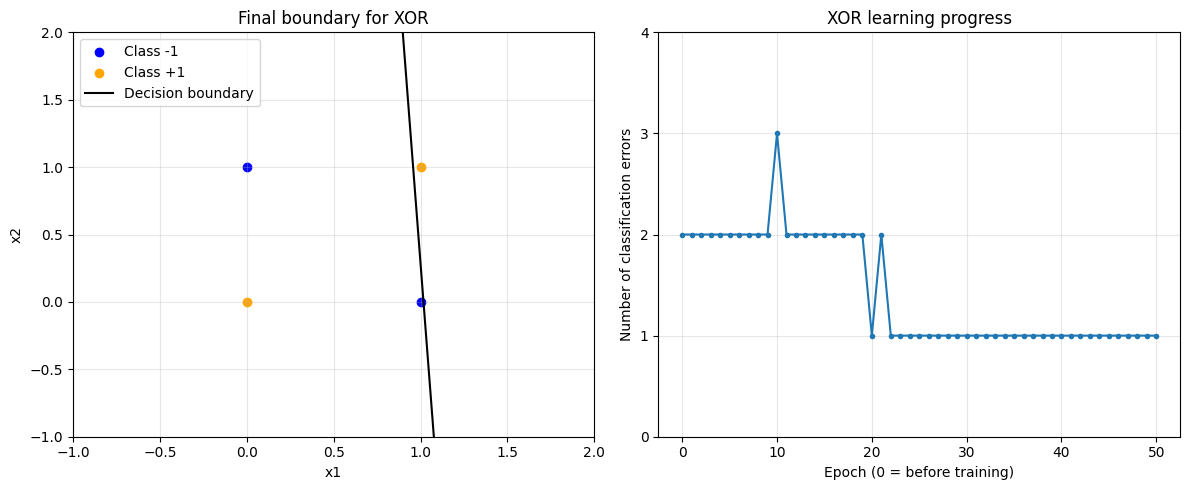

XOR errors after 50 epochs: 1
XOR accuracy: 75.0 %
The perceptron does not learn a perfect solution for this dataset.
The two classes cannot be separated by a single straight line.
A single perceptron can only learn a straight-line decision boundary.


In [24]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_decision_boundary(X_xor, y_xor, xor_weights, "Final boundary for XOR")

plt.subplot(1, 2, 2)
plt.plot(range(len(xor_error_history) + 1), [xor_initial_errors] + xor_error_history, marker="o", markersize=3)
plt.xlabel("Epoch (0 = before training)")
plt.ylabel("Number of classification errors")
plt.title("XOR learning progress")
plt.yticks(range(5))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

xor_errors = compute_loss(X_xor, y_xor, xor_weights)
print("XOR errors after", len(xor_error_history), "epochs:", xor_errors)
print("XOR accuracy:", (len(y_xor) - xor_errors) / len(y_xor) * 100, "%")
print("The perceptron does not learn a perfect solution for this dataset.")
print("The two classes cannot be separated by a single straight line.")
print("A single perceptron can only learn a straight-line decision boundary.")

In [25]:
import ipywidgets as widgets

def show_animation(X, y, weight_history, title):
    last_iteration = len(weight_history) - 1

    play = widgets.Play(
        value=0,
        min=0,
        max=last_iteration,
        step=1,
        interval=100,
        repeat=False
    )

    slider = widgets.IntSlider(
        value=0,
        min=0,
        max=last_iteration,
        description="Iteration",
        continuous_update=False
    )

    widgets.jslink((play, "value"), (slider, "value"))

    def draw(iteration):
        if iteration == 0:
            frame_title = title + " | Before training"
        else:
            epoch = (iteration - 1) // len(X) + 1
            example = (iteration - 1) % len(X) + 1
            frame_title = (
                f"{title} | Epoch {epoch} | "
                f"Example {example} | Iteration {iteration}"
            )

        frame_title += f"\nClassification errors: {compute_loss(X, y, weight_history[iteration])}"
        plt.figure(figsize=(7, 5))
        plot_decision_boundary(
            X, y, weight_history[iteration], frame_title
        )
        plt.tight_layout()
        plt.show()

    output = widgets.interactive_output(draw, {"iteration": slider})
    display(widgets.HBox([play, slider]), output)

In [26]:
animated_weights = final_weights.copy()
animated_errors = error_history.copy()

print("Animation ends at iteration:", len(weight_history) - 1)
print("Final classification errors:", compute_loss(X, y, animated_weights))
show_animation(X, y, weight_history, "Perceptron training")

Animation ends at iteration: 372
Final classification errors: 0


Output()

## XOR Training Animation

In [27]:
print("XOR animation ends at iteration:", len(xor_weight_history) - 1)
print("Final XOR classification errors:", compute_loss(X_xor, y_xor, xor_weights))
show_animation(X_xor, y_xor, xor_weight_history, "XOR training")

XOR animation ends at iteration: 200
Final XOR classification errors: 1


Output()